---
title: "L5-03 · Phase and interference"
short_title: "Phase and interference"
subtitle: "A phase on one path is invisible on its own, but a second beam splitter adds the two path amplitudes, so the relative phase $\\varphi$ becomes the count rate $\\frac{1 + \\cos\\varphi}{2}$; information about which path was taken shrinks that fringe."
description: "Predict the detection probabilities of a two-path interferometer after a relative phase change, and explain why a global phase and perfectly marked paths produce no fringe."
tags: [level-5, coursebook]
---

(lesson-l5-03)=

:::{div}
:class: qcai-meta
![Level 5 icon](../../_static/icons/qicon-level-5.svg) **Level 5 · Advanced undergraduate** · about 90 minutes  
**Big idea.** A phase on one path is invisible on its own, but a second beam splitter adds the two path amplitudes, so the relative phase $\varphi$ becomes the count rate $\frac{1 + \cos\varphi}{2}$; information about which path was taken shrinks that fringe.  
**Before this lesson.** [L5-02](#lesson-l5-02)  
**Lab.** [Interference](../../labs/04-interference.ipynb)
:::

## What you will be able to do

- Derive $P(0) = \frac{1 + \cos\varphi}{2} = \cos^2\frac{\varphi}{2}$ for the circuit $H$, $P(\varphi)$, $H$ and evaluate it for given phases.
- Show that a phase common to both paths, or applied before the first beam splitter, changes no probability, and that only the phase difference between the arms matters.
- Compute the fringe visibility $V = |\langle e_0|e_1\rangle|$ when the paths are marked by states $|e_0\rangle, |e_1\rangle$, and use $P(D0) = \frac{1 + V\cos\varphi}{2}$.
- Estimate an unknown phase from detector counts and state its standard error.

## Why this matters

Send single photons, one at a time, into an interferometer with two paths. Block one path and a quarter of the emitted photons reach detector D0: half are absorbed by the block, and half of the rest arrive at D0. Open both paths, and the fraction at D0 can be anything from 0 to 1 depending on a tiny change in one path length. So opening a second route can take D0 from a quarter of the photons to none at all. No story in which each photon takes one definite path, with probabilities that add, can produce that.

The amplitudes of [L5-01](#lesson-l5-01) explain it: amplitudes add before they are squared, so their relative phase decides whether they reinforce or cancel, exactly as the arrows $1$ and $e^{i\varphi}$ did in [L3-01](#lesson-l3-01). The Mach-Zehnder interferometer is the circuit $H$, phase, $H$ from [L5-02](#lesson-l5-02), and it is the template for interferometric sensors, for phase estimation in quantum algorithms, and for the question that recurs in quantum causal models: what changes when a record of the path exists?

:::{dropdown} Key terms

**Relative phase**
: The phase difference between the amplitudes of two alternatives that will later be added; it is what an interferometer measures.

**Phase gate**
: $P(\varphi) = \operatorname{diag}(1, e^{i\varphi})$, which adds the phase $\varphi$ to the $|1\rangle$ path only.

**Mach-Zehnder interferometer**
: Two beam splitters with two paths between them and a detector at each output port.

**Fringe**
: The oscillation of a detection probability as the relative phase is varied, here $\frac{1 + \cos\varphi}{2}$.

**Visibility**
: $V = \frac{P_{\max} - P_{\min}}{P_{\max} + P_{\min}}$, the contrast of a fringe; 1 for a perfect fringe and 0 for none.

**Which-path information**
: Any record, in another system, that is correlated with which path was taken; orthogonal records make the paths distinguishable in principle.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l5_03 as _lessonfigs

## Global phase and relative phase

[L5-01](#lesson-l5-01) proved that multiplying a whole state by $e^{i\gamma}$ changes no probability, and showed that a relative phase can. The **phase gate** $P(\varphi) = \operatorname{diag}(1, e^{i\varphi})$ adds a phase to one amplitude only. By itself it cannot be seen in the computational basis: $|\alpha|^2$ and $|e^{i\varphi}\beta|^2$ are unchanged. To see it, the two amplitudes must be brought together and added.

:::{prf:proposition} Only the phase difference matters
:label: prop-l5-03-relative
Replace $P(\varphi)$ by $\operatorname{diag}(e^{i\alpha}, e^{i\beta})$, a phase on each arm. Then every output probability depends on $\alpha$ and $\beta$ only through $\beta - \alpha$. In particular a phase $e^{i\gamma}$ added to both arms has no effect.
:::

:::{prf:proof}
$\operatorname{diag}(e^{i\alpha}, e^{i\beta}) = e^{i\alpha}\operatorname{diag}(1, e^{i(\beta - \alpha)}) = e^{i\alpha}P(\beta - \alpha)$. The factor $e^{i\alpha}$ passes through the remaining gates, which are linear, and multiplies the final state, where it is a global phase. With $\alpha = \beta = \gamma$ the gate is $e^{i\gamma}I$.
:::

:::{note} Phase relative to what?
A phase on a single amplitude has no meaning; a phase difference between two amplitudes that will later be added does. That is also why $P(\varphi)$ applied to $|0\rangle$ before the first beam splitter does nothing: $P(\varphi)|0\rangle = |0\rangle$, since there is no second amplitude yet.
:::

## The circuit H, phase, H

Put $|0\rangle$ through $H$, then $P(\varphi)$, then $H$. The first $H$ makes two equal amplitudes, the phase gate shifts one of them, and the second $H$ adds and subtracts them.

$$
H\,P(\varphi)\,H|0\rangle = \frac{1 + e^{i\varphi}}{2}\,|0\rangle + \frac{1 - e^{i\varphi}}{2}\,|1\rangle
$$ (eq-l5-03-output)

:::{prf:theorem} Two-path interference formula
:label: thm-l5-03-fringe
For the circuit $H$, $P(\varphi)$, $H$ acting on $|0\rangle$, the outcome probabilities are
:::

$$
P(0) = \frac{1 + \cos\varphi}{2} = \cos^2\frac{\varphi}{2}, \qquad P(1) = \frac{1 - \cos\varphi}{2} = \sin^2\frac{\varphi}{2}
$$ (eq-l5-03-fringe)

:::{prf:proof}
$H|0\rangle = \frac{1}{\sqrt2}(|0\rangle + |1\rangle)$, then $P(\varphi)$ gives $\frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$. Applying $H$ and collecting terms, $\frac12\big[(|0\rangle + |1\rangle) + e^{i\varphi}(|0\rangle - |1\rangle)\big]$, which is [](#eq-l5-03-output). By the Born rule and $|1 \pm e^{i\varphi}|^2 = 2 \pm 2\cos\varphi$ (from [L3-01](#lesson-l3-01)), $P(0) = \frac{2 + 2\cos\varphi}{4}$ and $P(1) = \frac{2 - 2\cos\varphi}{4}$. The half-angle identities give the second forms.
:::

:::{figure} ../../_static/animations/l5_03_interference_derivation.mp4
:alt: The circuit zero, H, phase gate, H at the top; below it the state is rewritten step by step into amplitudes one plus e to the i phi over two and one minus e to the i phi over two, and the probability of zero is simplified to one plus cos phi over two.
:width: 100%

The derivation of [](#eq-l5-03-fringe), one transformation at a time, and the two ways a phase can fail to matter.
:::

:::{dropdown} What the animation shows
At the top the circuit $|0\rangle \to H \to P(\varphi) \to H$ is shown, with $P(\varphi) = \begin{pmatrix}1&0\\0&e^{i\varphi}\end{pmatrix}$. Below, the expression $H\,P(\varphi)\,H|0\rangle$ is rewritten in place: first as $H\,P(\varphi)\,\frac{1}{\sqrt2}(|0\rangle + |1\rangle)$, then as $H\,\frac{1}{\sqrt2}(|0\rangle + e^{i\varphi}|1\rangle)$, then as $\frac{1 + e^{i\varphi}}{2}|0\rangle + \frac{1 - e^{i\varphi}}{2}|1\rangle$. Under it, $P(0) = \frac14|1 + e^{i\varphi}|^2$ becomes $\frac14(2 + 2\cos\varphi)$ and then $\frac{1 + \cos\varphi}{2} = \cos^2\frac{\varphi}{2}$, which is boxed, with a note that this is the same $2 + 2\cos\varphi$ as for two unit arrows in L3-01. Three closing lines state that a phase on both arms, $e^{i\gamma}I$, is global and changes nothing; that a phase before the first $H$ does nothing because $P(\varphi)|0\rangle = |0\rangle$; and that only the phase between the arms, between the two Hadamards, matters.
:::

Some values: $\varphi = 0$ gives $P(0) = 1$ (the amplitudes reinforce at 0 and cancel at 1), $\varphi = \pi/2$ gives $\frac12$, $\varphi = 2\pi/3$ gives $0.25$, and $\varphi = \pi$ gives $P(0) = 0$. On the Bloch sphere, the first $H$ moves $|0\rangle$ to $|+\rangle$, the phase turns it by $\varphi$ about $z$ to $(\cos\varphi, \sin\varphi, 0)$, and the second $H$, which maps $(x, y, z) \mapsto (z, -y, x)$, lifts it to $(0, -\sin\varphi, \cos\varphi)$. Its height is $\cos\varphi$, so $P(0) = \frac{1 + z}{2}$ reproduces [](#eq-l5-03-fringe).

## The Mach-Zehnder interferometer

In a Mach-Zehnder interferometer a photon meets a balanced beam splitter, travels along path 0 or path 1, passes a phase shifter that delays path 1 by a phase $\varphi$, and meets a second beam splitter in front of detectors D0 and D1. Treat the path as a qubit, $|0\rangle$ for path 0 and $|1\rangle$ for path 1, and model each beam splitter as $H$. Then the device is the circuit of the previous section, and [](#eq-l5-03-fringe) is its fringe [@feynman; @nielsenchuang].

```{mermaid}
graph LR
  S[photon source] --> B1[beam splitter 1, modeled as H]
  B1 -->|path 0| M0[mirror]
  B1 -->|path 1| PS[phase shifter φ]
  M0 --> B2[beam splitter 2, modeled as H]
  PS --> B2
  B2 --> D0[detector D0]
  B2 --> D1[detector D1]
```

*The interferometer as a flow: the path is the qubit, the beam splitters are Hadamards, and the phase shifter is the gate P(φ) on path 1.*

Read [](#eq-l5-03-output) as a sum over paths. To reach D0, the photon can take path 0 (amplitude $\frac{1}{\sqrt2}\cdot\frac{1}{\sqrt2} = \frac12$) or path 1 (amplitude $\frac12 e^{i\varphi}$). The amplitudes of the two indistinguishable alternatives add: $\frac12 + \frac12 e^{i\varphi}$. For D1 the second beam splitter contributes a minus sign on path 1, giving $\frac12 - \frac12 e^{i\varphi}$.

:::{figure} ../../_static/animations/l5_03_mach_zehnder_live.mp4
:alt: A Mach-Zehnder interferometer with a phase shifter on the lower arm. As the phase increases, two amplitude arrows add head to tail, detector bars rise and fall, and a graph traces one plus cos phi over two.
:width: 100%

As the phase $\varphi$ sweeps once around, the amplitude at D0, $\frac12 + \frac12 e^{i\varphi}$, shrinks to zero and grows back, and $P(D0) = \frac{1 + \cos\varphi}{2}$ is traced live.
:::

:::{dropdown} What the animation shows
On the left, the interferometer is drawn: a source, a first beam splitter labeled H, an upper path 0 via a mirror, a lower path 1 through an amber phase shifter labeled $\varphi$, a second beam splitter labeled H, and detectors D0 and D1. Below it, two bars show the probabilities at D0 (violet) and D1 (cyan). At the top right, the amplitude at D0 is drawn as a blue arrow $\frac12$ followed by an amber arrow $\frac12 e^{i\varphi}$, with their red sum, under the label amplitude at D0 $= \frac12 + \frac12 e^{i\varphi}$. At the bottom right, axes show $P(D0) = \frac{1 + \cos\varphi}{2}$ for $\varphi$ from 0 to $2\pi$, with the D1 curve faint. As $\varphi$ increases from 0, the amber arrow turns, the sum shrinks, the D0 bar falls and the D1 bar rises, and a violet dot traces the fringe. The sweep pauses at $\varphi = \frac{2\pi}{3}$, where $P(D0) = 0.25$, then completes the turn. Closing notes: at $\varphi = 0$ every photon reaches D0, and at $\varphi = \pi$ every photon reaches D1.
:::


In [2]:
_show(_lessonfigs.fringe_explorer())

**Explore.** Drag the phase. Left: the two path amplitudes that reach D0 and their sum. Right: $P(D0)$ and $P(D1)$, with a dashed fringe of visibility 0.5 for comparison.

:::{dropdown} What the figure shows
The first panel shows, in the complex plane, a blue arrow from 0 to $\frac12$ (path 0) and an amber arrow $\frac12 e^{i\varphi}$ attached to its tip (path 1), with their sum as a red dashed arrow; the tip moves on a dotted circle of radius $\frac12$ centered at $\frac12$. The second panel plots $P(D0) = \frac{1 + \cos\varphi}{2}$ and $P(D1) = \frac{1 - \cos\varphi}{2}$ for $\varphi$ from $0^\circ$ to $360^\circ$, plus a dashed curve $\frac{1 + 0.5\cos\varphi}{2}$ for partly marked paths. A slider moves $\varphi$ in steps of $15^\circ$ and a red marker shows the current $P(D0)$: 1 at $0^\circ$, 0.5 at $90^\circ$, 0 at $180^\circ$.
:::

:::{prf:remark} Which port is bright depends on the beam-splitter convention
A physical lossless 50:50 beam splitter is often written $B = \frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$, which differs from $H$ by phases on the ports. With $B$ in place of both Hadamards the probability at port 0 is $\frac{1 - \cos\varphi}{2}$: the same fringe, with the bright and dark ports exchanged at $\varphi = 0$. Port labels and phase offsets are conventions; the fringe shape and its visibility are not.
:::

## Which-path information and visibility

Suppose each path leaves a mark in another system, a marker that ends in state $|e_0\rangle$ if the photon took path 0 and $|e_1\rangle$ if it took path 1. Between the beam splitters the joint state is $\frac{1}{\sqrt2}(|0\rangle|e_0\rangle + e^{i\varphi}|1\rangle|e_1\rangle)$, and only the path goes through the second $H$.

:::{prf:theorem} Visibility equals marker overlap
:label: thm-l5-03-visibility
Write $\langle e_0|e_1\rangle = V e^{i\delta}$ with $V \ge 0$. Then $P(D0) = \frac{1 + V\cos(\varphi + \delta)}{2}$, and the fringe visibility is $V = |\langle e_0|e_1\rangle|$. In particular, perfectly distinguishable markers ($\langle e_0|e_1\rangle = 0$) give $P(D0) = \frac12$ for every $\varphi$: no fringe.
:::

:::{prf:proof}
Apply $H$ to the path: $\frac12\big[(|0\rangle + |1\rangle)|e_0\rangle + e^{i\varphi}(|0\rangle - |1\rangle)|e_1\rangle\big]$. The part with path $|0\rangle$ is $|0\rangle \otimes \frac12(|e_0\rangle + e^{i\varphi}|e_1\rangle)$, so the Born rule for the outcome D0 (summing over the unobserved marker) gives $P(D0) = \frac14\big\||e_0\rangle + e^{i\varphi}|e_1\rangle\big\|^2 = \frac14\big(2 + 2\operatorname{Re}(e^{i\varphi}\langle e_0|e_1\rangle)\big) = \frac{1 + V\cos(\varphi + \delta)}{2}$. Its maximum and minimum over $\varphi$ are $\frac{1 \pm V}{2}$, so $\frac{P_{\max} - P_{\min}}{P_{\max} + P_{\min}} = V$.
:::

$$
P(D0) = \frac{1 + V\cos\varphi}{2}, \qquad V = |\langle e_0|e_1\rangle| \quad (\text{taking } \delta = 0)
$$ (eq-l5-03-visibility)

:::{prf:remark} A preview of mixed states
Once the path is entangled with a marker, the path alone is no longer described by a state vector. [L5-05](#lesson-l5-05) describes it by a density operator, drawn as a point inside the Bloch sphere; here that point lies at distance $V$ from the center, and the rule $P(0) = \frac{1 + z}{2}$ still holds for it. The animation below uses this picture before L5-05 justifies it.
:::

:::{figure} ../../_static/animations/l5_03_phase_on_bloch.mp4
:alt: On a Bloch sphere, H moves the state from the north pole to the equator, the phase turns it about the vertical axis, and the second H lifts it onto a vertical circle; then the arrow sweeps round that circle with a live probability readout, and finally shrinks to half length so the readout only swings between 0.25 and 0.75.
:width: 100%

The same circuit on the Bloch sphere: the output height is $\cos\varphi$, so $P(0) = \frac{1 + \cos\varphi}{2}$. Marking the path shrinks the vector to length $V$ and the fringe to $\frac{1 + V\cos\varphi}{2}$.
:::

:::{dropdown} What the animation shows
A Bloch sphere shows the state at $|0\rangle$, with the circuit $|0\rangle \to H \to P(\varphi) \to H$ written beside it. The first $H$ swings the arrow through a half turn about the diagonal axis to $|+\rangle$ on the equator (cyan trail). The phase turns it about the vertical axis by $\varphi = \frac{2\pi}{3}$ (amber trail). The second $H$ swings it onto the vertical circle through the $y$ and $z$ axes (blue trail), ending at height $z = -\frac12$, so $P(0) = 0.25$. Then the phase is swept through a full turn: the output arrow runs round the vertical circle while a dashed amber line projects it onto the $z$ axis and a readout shows $P(0) = \frac{1 + z}{2}$, following $P(0) = \frac{1 + \cos\varphi}{2}$. Finally, with the label mark the path, the arrow shrinks to length $V = 0.5$ and the rule becomes $P(0) = \frac{1 + V\cos\varphi}{2}$; during a second sweep the readout only swings between 0.25 and 0.75.
:::


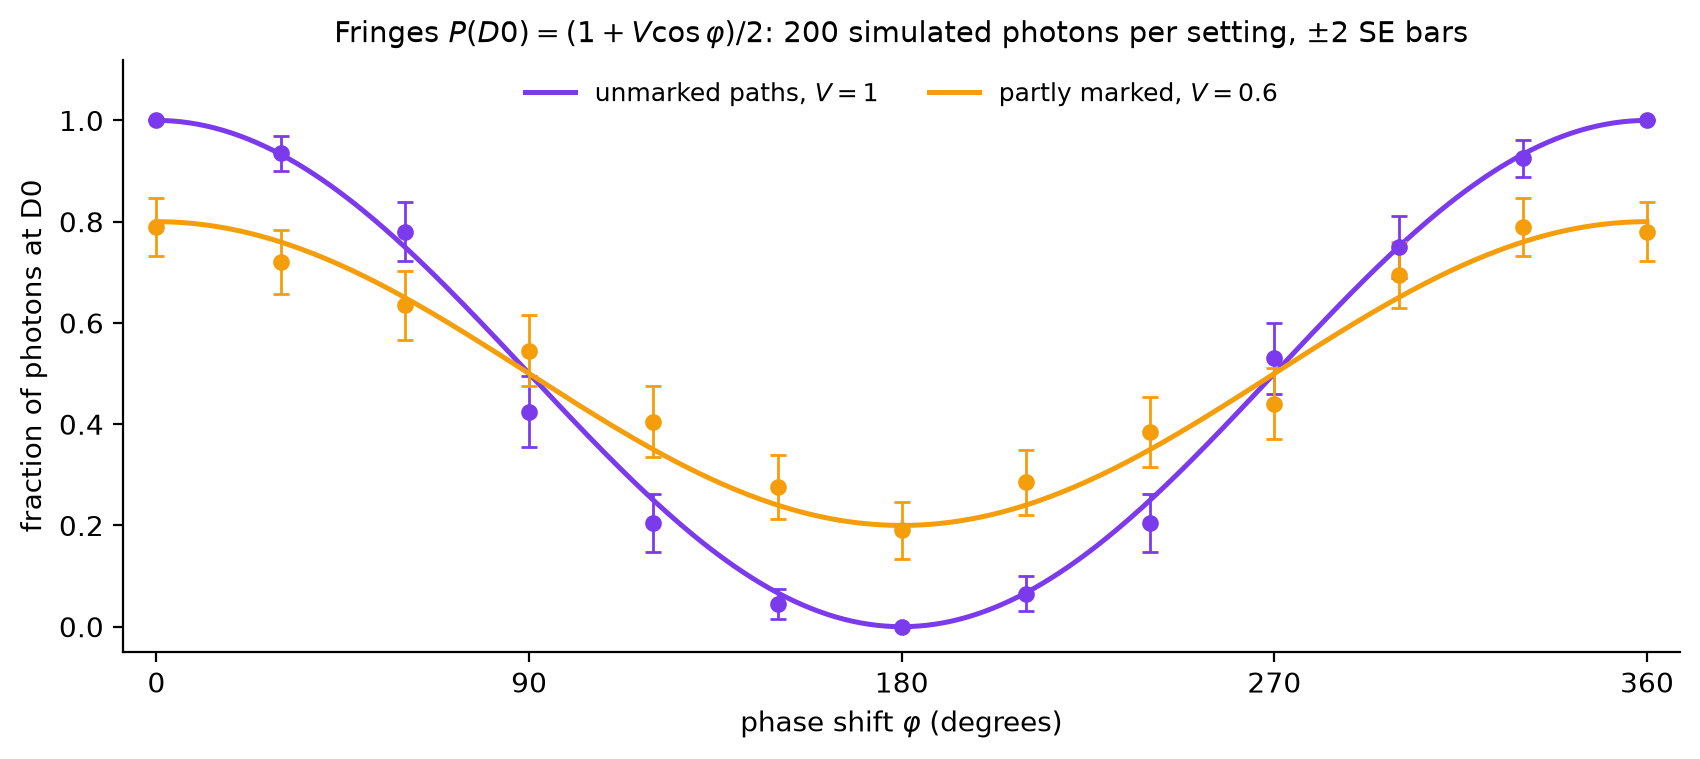

In [3]:
_show_mpl(_lessonfigs.fringe_data())

*Simulated counts of 200 photons at each of 13 phase settings, with $\pm 2$ standard-error bars, against $P(D0) = \frac{1 + V\cos\varphi}{2}$ for unmarked paths ($V = 1$) and partly marked paths ($V = 0.6$). Visibility is read off as the half-height of the fringe divided by its mean.*

:::{prf:remark} Random phase noise also lowers visibility
If the phase fluctuates from photon to photon by a random amount $\Theta$, averaging $\frac{1 + \cos(\varphi + \Theta)}{2}$ gives $\frac{1 + \operatorname{Re}(e^{i\varphi}\,\mathbb{E}[e^{i\Theta}])}{2}$, which has the same form with $V = |\mathbb{E}[e^{i\Theta}]|$. For $\Theta$ uniform on $[-a, a]$, $V = \frac{\sin a}{a}$. Dephasing of this kind is a quantum channel, studied in [L5-06](#lesson-l5-06).
:::

## Compute it

Check the fringe formula, the two ways a phase can fail to matter, the symmetric beam-splitter convention, visibility from marker overlap, and a phase estimate from seeded counts.


In [4]:
import numpy as np
from qcai import science

H, ket0 = science.H, science.KET0
def P(phi):
    return np.diag([1, np.exp(1j * phi)])

# 1. the fringe of the circuit H, P(phi), H
for deg in (0, 60, 90, 120, 180):
    phi = np.radians(deg)
    out = H @ P(phi) @ H @ ket0
    print(f'phi = {deg:3d} deg   P(D0) = {abs(out[0]) ** 2:.4f}   (1 + cos phi)/2 = {(1 + np.cos(phi)) / 2:.4f}')

# 2. only the relative phase matters
phi = np.radians(60)
both = H @ np.diag([np.exp(0.9j), np.exp(0.9j + 1j * phi)]) @ H @ ket0     # extra phase 0.9 on both arms
print('extra phase on both arms, P(D0):', round(abs(both[0]) ** 2, 4))
print('phase before the first H changes nothing:', np.allclose(P(phi) @ ket0, ket0))

# 3. a symmetric beam splitter (1/sqrt2)[[1, i], [i, 1]] swaps which port is bright
B = np.array([[1, 1j], [1j, 1]]) / np.sqrt(2)
for deg in (0, 90, 180):
    out = B @ P(np.radians(deg)) @ B @ ket0
    print(f'symmetric splitters, phi = {deg:3d} deg: P(port 0) = {abs(out[0]) ** 2:.4f}')

# 4. which-path marker states: visibility V = |<e0|e1>|
def p_d0(phi, e0, e1):
    psi = (np.kron([1, 0], e0) + np.exp(1j * phi) * np.kron([0, 1], e1)) / np.sqrt(2)
    out = np.kron(H, np.eye(2)) @ psi
    return float(np.sum(np.abs(out[:2]) ** 2))
e0, e1 = np.array([1, 0]), np.array([np.cos(np.pi / 3), np.sin(np.pi / 3)])
pmax, pmin = p_d0(0, e0, e1), p_d0(np.pi, e0, e1)
print('marker overlap', round(abs(np.vdot(e0, e1)), 4), ' Pmax', round(pmax, 4), ' Pmin', round(pmin, 4),
      ' visibility', round((pmax - pmin) / (pmax + pmin), 4))

# 5. estimate an unknown phase from 1000 photons (seeded simulation)
true_phi = np.radians(50)
run = science.trials((1 + np.cos(true_phi)) / 2, 1000, seed=3)
f = run['frequency']
phi_hat = np.arccos(2 * f - 1)
se_phi = np.sqrt(f * (1 - f) / 1000) / (np.sin(phi_hat) / 2)
print(f'D0 fraction {f:.3f}  ->  phi estimate {np.degrees(phi_hat):.1f} deg  (SE about {np.degrees(se_phi):.1f} deg, true 50)')

phi =   0 deg   P(D0) = 1.0000   (1 + cos phi)/2 = 1.0000
phi =  60 deg   P(D0) = 0.7500   (1 + cos phi)/2 = 0.7500
phi =  90 deg   P(D0) = 0.5000   (1 + cos phi)/2 = 0.5000
phi = 120 deg   P(D0) = 0.2500   (1 + cos phi)/2 = 0.2500
phi = 180 deg   P(D0) = 0.0000   (1 + cos phi)/2 = 0.0000
extra phase on both arms, P(D0): 0.75
phase before the first H changes nothing: True
symmetric splitters, phi =   0 deg: P(port 0) = 0.0000
symmetric splitters, phi =  90 deg: P(port 0) = 0.5000
symmetric splitters, phi = 180 deg: P(port 0) = 1.0000
marker overlap 0.5  Pmax 0.75  Pmin 0.25  visibility 0.5
D0 fraction 0.832  ->  phi estimate 48.4 deg  (SE about 1.8 deg, true 50)


:::{warning} Reading phase from counts has blind spots
Since $\cos(-\varphi) = \cos\varphi$, counts at one setting cannot tell $\varphi$ from $-\varphi$, and near $\varphi = 0$ or $\pi$ the fringe is flat, so the phase error blows up. Interferometric sensors therefore work near $\varphi = \pi/2$, where $|dP/d\varphi| = \frac12$ is largest, and add known offsets to resolve the sign.
:::

## Worked example

:::{admonition} A phase of sixty degrees, with and without a marker
:class: tip

A Mach-Zehnder interferometer (beam splitters modeled as $H$) has relative phase $\varphi = \pi/3$. Find $P(D0)$ and the expected count at D0 for 1000 photons. Then the paths are marked with states of overlap $\langle e_0|e_1\rangle = 0.6$: find the new $P(D0)$. Which phase gives $P(D0) = 0.9$ in each case?

1. Unmarked: $P(D0) = \frac{1 + \cos 60^\circ}{2} = \frac{1 + 0.5}{2} = 0.75$, so the expected count is $1000 \cdot 0.75 = 750$.
2. Check by amplitudes: $\frac12(1 + e^{i\pi/3}) = \frac12(1.5 + 0.866i)$, whose squared modulus is $\frac14(2.25 + 0.75) = 0.75$.
3. Marked: by [](#eq-l5-03-visibility) with $V = 0.6$ and $\delta = 0$, $P(D0) = \frac{1 + 0.6 \cdot 0.5}{2} = 0.65$, an expected 650 photons.
4. Target 0.9: unmarked, $\cos\varphi = 2(0.9) - 1 = 0.8$, so $\varphi = \pm 36.87^\circ$. Marked, the largest value is $\frac{1 + 0.6}{2} = 0.8$, so 0.9 cannot be reached at any phase.

**Result.** $P(D0) = 0.75$ (750 of 1000) unmarked and $0.65$ with marker overlap 0.6; $P(D0) = 0.9$ needs $\varphi = \pm 36.87^\circ$ unmarked and is impossible with $V = 0.6$, whose fringe stays between 0.2 and 0.8.
:::

## Exercises

**1. (Core)** Give $P(D0)$ and $P(D1)$ for $\varphi = 0, \pi/2, \pi, 3\pi/2$ in the $H$-modeled interferometer.

:::{dropdown} Solution
From [](#eq-l5-03-fringe): $\varphi = 0$: $(1, 0)$; $\pi/2$: $(\frac12, \frac12)$; $\pi$: $(0, 1)$; $3\pi/2$: $(\frac12, \frac12)$. The two always add to 1.
:::

**2. (Core)** Phase shifters put $\alpha = 0.4$ on path 0 and $\beta = 1.4$ on path 1 (radians). Find $P(D0)$, and say what changes if both phases are increased by 2.

:::{dropdown} Solution
Only $\beta - \alpha = 1$ matters (Proposition [](#prop-l5-03-relative)), so $P(D0) = \frac{1 + \cos 1}{2} \approx \frac{1 + 0.5403}{2} \approx 0.770$. Adding 2 to both leaves $\beta - \alpha = 1$, so nothing changes.
:::

**3. (Stretch)** Replace both Hadamards by the symmetric beam splitter $B = \frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$. Compute the amplitude and probability at port 0 for $|0\rangle$ input.

:::{dropdown} Solution
$B|0\rangle = \frac{1}{\sqrt2}(|0\rangle + i|1\rangle)$; the phase gate gives $\frac{1}{\sqrt2}(|0\rangle + ie^{i\varphi}|1\rangle)$; the second $B$ gives port-0 amplitude $\frac12(1 + i \cdot i e^{i\varphi}) = \frac12(1 - e^{i\varphi})$. So $P(\text{port } 0) = \frac{2 - 2\cos\varphi}{4} = \frac{1 - \cos\varphi}{2}$: the dark port at $\varphi = 0$.
:::

**4. (Stretch)** In 1000 photons, 820 reach D0. Estimate $|\varphi|$ and its standard error, and explain why the sign of $\varphi$ is not determined.

:::{dropdown} Solution
$\hat P = 0.82$ gives $\cos\hat\varphi = 2(0.82) - 1 = 0.64$, so $|\hat\varphi| \approx 50.2^\circ$. The standard error of $\hat P$ is $\sqrt{0.82 \cdot 0.18/1000} \approx 0.0121$. Since $dP/d\varphi = -\frac12\sin\varphi$, the phase error is about $0.0121/(\frac12\sin 50.2^\circ) \approx 0.0121/0.384 \approx 0.032$ rad, about $1.8^\circ$. Because $\cos$ is even, $\varphi$ and $-\varphi$ give the same counts.
:::

**5. (Challenge)** The marker is a qubit with $|e_0\rangle = |0\rangle$ and $|e_1\rangle = \cos\theta|0\rangle + \sin\theta|1\rangle$. Find the visibility as a function of $\theta$, and the value of $\theta$ at which a measurement of the marker can tell the paths apart with certainty.

:::{dropdown} Solution
$\langle e_0|e_1\rangle = \cos\theta$, so by Theorem [](#thm-l5-03-visibility) $V = |\cos\theta|$ and $P(D0) = \frac{1 + \cos\theta\cos\varphi}{2}$ for $\cos\theta \ge 0$. The markers are orthogonal at $\theta = \pi/2$, where a computational-basis measurement of the marker reveals the path with certainty and $V = 0$. Visibility and distinguishability trade off continuously in between.
:::

**6. (Challenge)** Show that the fringe visibility of $P(D0) = \frac{1 + V\cos(\varphi + \delta)}{2}$ is $V$, and that when the phase noise $\Theta$ is uniform on $[-a, a]$ the visibility is $\frac{\sin a}{a}$.

:::{dropdown} Solution
Over $\varphi$, $P$ ranges from $\frac{1 - V}{2}$ to $\frac{1 + V}{2}$, so $\frac{P_{\max} - P_{\min}}{P_{\max} + P_{\min}} = \frac{V}{1} = V$. For the noise, $\mathbb{E}[e^{i\Theta}] = \frac{1}{2a}\int_{-a}^{a} e^{it}\,dt = \frac{e^{ia} - e^{-ia}}{2ia} = \frac{\sin a}{a}$, which is real and non-negative for $0 < a \le \pi$, so the averaged fringe is $\frac{1 + \frac{\sin a}{a}\cos\varphi}{2}$ and $V = \frac{\sin a}{a}$.
:::

## Check your understanding

**1. In the $H$-modeled interferometer, what is $P(D0)$ when $\varphi = \pi$?**

- **A.** 1
- **B.** $\frac14$
- **C.** 0
- **D.** $\frac12$

:::{dropdown} Show the answer
**C. 0**

$P(D0) = \frac{1 + \cos\pi}{2} = 0$: the two path amplitudes $\frac12$ and $-\frac12$ cancel at D0, and every photon reaches D1.
:::

**2. Which change leaves all detection probabilities unchanged?**

- **A.** Adding a phase $\pi$ to one arm
- **B.** Adding a phase $\pi/2$ to one arm
- **C.** Adding the same phase to both arms
- **D.** Recording which path each photon took

:::{dropdown} Show the answer
**C. Adding the same phase to both arms**

A common phase factors out as a global phase. A phase on one arm changes $\varphi$, and a which-path record lowers the visibility to $|\langle e_0|e_1\rangle|$.
:::

**3. The two paths are marked by orthogonal states of a marker system. What does D0 record as the phase is varied?**

- **A.** $P(D0) = 0$ for every phase
- **B.** $P(D0) = \frac12$ for every phase
- **C.** The same fringe $\frac{1 + \cos\varphi}{2}$
- **D.** A fringe with half the period

:::{dropdown} Show the answer
**B. $P(D0) = \frac12$ for every phase**

With $\langle e_0|e_1\rangle = 0$ the visibility is 0, so $P(D0) = \frac12$ whatever $\varphi$ is: the paths no longer interfere.
:::

**4. What is $|1 + e^{i\pi/2}|^2$?** *(Review of [L3-01](#lesson-l3-01))*

- **A.** 0
- **B.** 4
- **C.** 1
- **D.** 2

:::{dropdown} Show the answer
**D. 2**

$|1 + i|^2 = 1^2 + 1^2 = 2$, which agrees with $2 + 2\cos\frac{\pi}{2} = 2$.
:::

## Common misconceptions

- **"Phase can never be measured, because probabilities only use squared magnitudes."** A global phase cannot be measured. A relative phase becomes a probability as soon as the two amplitudes are added, here by the second beam splitter: $P(D0) = \frac{1 + \cos\varphi}{2}$.
- **"Each photon really takes one path; we just do not know which."** If each photon took path 0 or path 1 with probability $\frac12$ each, and each path alone gives D0 half the time, then $P(D0) = \frac12$ for every $\varphi$. That is exactly the no-fringe prediction for perfectly marked paths, and it contradicts the observed fringe with unmarked paths.
- **"Interference needs many photons interfering with each other."** The fringe appears with one photon at a time; each photon's two path amplitudes interfere, and the pattern builds up in the counts [@feynman].
- **"Which-path information destroys interference only because detecting the photon kicks it."** No kick is needed. Theorem [](#thm-l5-03-visibility) shows that the visibility equals $|\langle e_0|e_1\rangle|$: correlation with orthogonal marker states is enough, even if the marker is never read.

:::{caution} Scope and limits
This lesson models an ideal, lossless, balanced interferometer with each beam splitter written as $H$; a real 50:50 beam splitter is often written $\frac{1}{\sqrt2}\begin{pmatrix}1 & i\\ i & 1\end{pmatrix}$, which shifts the fringe (swapping the bright and dark ports) without changing its shape or visibility. The photon is treated as a single path qubit; photon statistics, mode matching, losses and detector efficiency are ignored. The fringe data in the figure and code come from a seeded pseudo-random simulation, not an experiment. The marker model assumes the marker interacts only with the path and is not measured in a way that is post-selected on.
:::

:::{seealso} Where this leads
The fringe $\frac{1 + V\cos\varphi}{2}$ is a one-qubit measurement of the Bloch vector's $x$ component after the phase, and its loss of visibility is the shrinking Bloch vector of [L5-05](#lesson-l5-05) and the dephasing channel of [L5-06](#lesson-l5-06). Entanglement with a marker is the theme of [L5-04](#lesson-l5-04). In quantum causal modeling, a which-path record is a variable that the paths influence; whether it is read or not changes what the detectors can show.
:::

:::{dropdown} For instructors

**Why this lesson.** Interference is where amplitudes stop being bookkeeping and become physics: the single fact that amplitudes add before squaring explains the fringe, the irrelevance of global phase, and the loss of fringes with which-path information [@feynman; @nielsenchuang].

**Teaching notes.**

- Start with the blocked-path experiment and ask for a classical prediction ($\frac12$ at D0) before showing the fringe.
- Connect the phasor panel of the explorer to the arrows of [L3-01](#lesson-l3-01): the sum $\frac12 + \frac12 e^{i\varphi}$ is half of $1 + e^{i\varphi}$.
- Do the symmetric beam-splitter exercise in class to show that port labels are a convention but visibility is not.
- Use the marker challenge to discuss complementarity quantitatively: visibility $|\cos\theta|$ against distinguishability of the markers.

**Assessment.** The worked example and the first stretch exercise check whether students can derive the fringe in either convention; the first challenge exercise checks whether they can apply the visibility theorem to a concrete marker.

**Going further.** Phase estimation turns repeated interferometry into a quantum algorithm (Nielsen and Chuang, Section 5.2) [@nielsenchuang]. Preskill's notes discuss decoherence as entanglement with an environment, which is the marker picture in general form [@preskill]. Wave interference in introductory physics gives the classical counterpart [@openstax_interference].

:::

## References

This lesson draws on [@feynman; @nielsenchuang; @preskill; @ibm; @openstax_interference].

**Further reading.**

- [@feynman]: Volume III, chapters 1 and 3: amplitudes for alternatives, and how distinguishable alternatives stop interfering.
- [@ibm]: The Basics of quantum information course builds the same H, phase, H circuits on simulators and hardware.

**Next:** [L5-04 · Tensor products and entanglement](#lesson-l5-04)
